# Part 9, notebook 3 of 5: which cases to send

Companion to *Human in the Loop*. The five notebooks follow the post in order. Each explains the idea with a daily-life picture, shows the real source, and runs it. **Cells marked "Your turn" are for you to change and rerun.**

| # | Notebook | Post section | Needs the model server? |
|---|---|---|---|
| 09a | `09a_where_a_human_belongs` | Where a person belongs in the pipeline | no |
| 09b | `09b_pause_and_resume` | Pause, ask, resume: `interrupt()` | no |
| 09c | `09c_who_to_ask` | Which cases to send: the review budget | no (reads the saved Part 8 runs) |
| 09d | `09d_does_the_human_help` | Does the human step help, and what does it cost? | no (reads the saved Part 7 runs) |
| 09e | `09e_queue_and_failures` | The review queue and what goes wrong | one cell uses the model server |

**The picture.** A triage nurse. A hospital cannot have a doctor look at everyone, so the nurse sends the people she is least sure about to the doctor first. The question is not "does the nurse have opinions" but "when she says *I'm unsure*, is she actually the one who is wrong more often?"

Part 8 left a promise: the typed models' probabilities are what the review threshold would be set on. This notebook tests it. For every held-out box (513 of them, 81 real) a **judge** gave a probability. We let the judge decide alone, then let a person re-check the boxes the judge was **least sure** about, and count how many of the judge's mistakes that fixes.

In [1]:
import sys, json, os
from pathlib import Path
os.environ.setdefault("AGENTIC_ZERO_MODEL", "qwen3.8-27b")   # the model name the local vLLM server serves (only 09e calls it)
import warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path("..").resolve()))                # this notebook lives in literate/, the code in notebooks/agentic-zero-to-advanced/
OUT = Path("..").resolve() / "out"
%matplotlib inline
import hitl_budget as hb
import matplotlib.pyplot as plt

## How "least sure" is measured

Take every box's probability, rank them, and call a box *uncertain* when its rank is close to the rank of the decision threshold. We use ranks because some judges' raw probabilities are badly scaled (Part 8 measured that). Three lines for each judge:

- **the judge's choice**: re-check the least sure boxes first,
- **random**: re-check boxes picked by chance (the line to beat),
- **best possible**: re-check the judge's actual mistakes first (needs the answer, so it is only a ceiling).

In [2]:
print(json.dumps(hb.curve("llm-logprob", "plain")["curve"][:4], indent=0))
print("...each point: k boxes re-checked -> mistakes left (judge's choice | random | best possible)")

[
{
"k": 0,
"errors_left": 242,
"random_left": 242.0,
"best_left": 242
},
{
"k": 5,
"errors_left": 240,
"random_left": 239.64132553606237,
"best_left": 237
},
{
"k": 10,
"errors_left": 236,
"random_left": 237.28265107212476,
"best_left": 232
},
{
"k": 15,
"errors_left": 235,
"random_left": 234.92397660818716,
"best_left": 227
}
]
...each point: k boxes re-checked -> mistakes left (judge's choice | random | best possible)


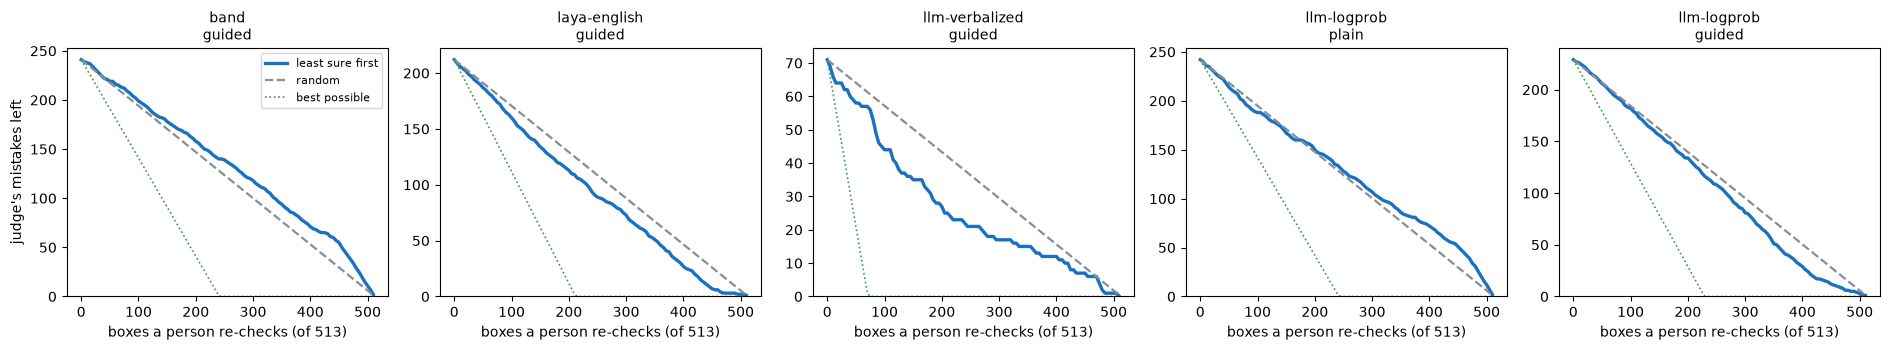

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(19, 3.6), sharey=False)
for ax, (name, tag) in zip(axes, hb.JUDGES):
    c = hb.curve(name, tag)
    ks = [p["k"] for p in c["curve"]]
    ax.plot(ks, [p["errors_left"] for p in c["curve"]], lw=2.4, color="#1971c2", label="least sure first")
    ax.plot(ks, [p["random_left"] for p in c["curve"]], lw=1.6, ls="--", color="#868e96", label="random")
    ax.plot(ks, [p["best_left"] for p in c["curve"]], lw=1.2, ls=":", color="#2f9e44", label="best possible")
    ax.set_title(f"{name}\n{tag}", fontsize=10)
    ax.set_xlabel("boxes a person re-checks (of 513)")
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("judge's mistakes left")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## The numbers behind the lines

`fixed@25%` is how many of the judge's mistakes disappear if a person re-checks the 25% least sure boxes. `random@25%` is what picking boxes by chance would have fixed. The gap between the two is the value of the judge's uncertainty.

In [4]:
rows = [hb.summary_row(hb.curve(n, t)) for n, t in hb.JUDGES]
print(f"{'judge':24s} {'mistakes':>8s} | {'fixed@10%':>9s} {'random':>7s} | {'fixed@25%':>9s} {'random':>7s} | {'fixed@50%':>9s} {'random':>7s}")
for r in rows:
    print(f"{r['judge']:24s} {r['errors']:8d} | {r['fixed@10%']:9.0f} {r['random@10%']:7.1f} | {r['fixed@25%']:9.0f} {r['random@25%']:7.1f} | {r['fixed@50%']:9.0f} {r['random@50%']:7.1f}")

judge                    mistakes | fixed@10%  random | fixed@25%  random | fixed@50%  random
band/guided                   241 |        22    23.5 |        56    61.1 |       104   119.8
laya-english/guided           212 |        25    20.7 |        69    53.7 |       124   105.4
llm-verbalized/guided          71 |        13     6.9 |        34    18.0 |        50    35.3
llm-logprob/plain             242 |        28    23.6 |        64    61.3 |       116   120.3
llm-logprob/guided            229 |        23    22.3 |        64    58.0 |       123   113.8


## Reading it

- For `llm-verbalized/guided` the uncertainty is worth about **twice** random choice (34 mistakes fixed at 25% against 18 for chance).
- For the rule and for `llm-logprob/plain` the least-sure boxes are **no better than random ones**. A person's time sent by that signal is no better spent than a coin flip. `laya-english` and `llm-logprob/guided` are only modestly better than chance.
- Part 8 found that these judges rank real defects against false alarms only modestly (AUC about 0.6 to 0.7). That is why. You cannot route well on a signal that barely separates the two groups.

**Takeaway for the pipeline.** Do not assume "low confidence" means "send to a person". Measure the curve first, like this, and compare it with random. Part 7's pipeline therefore also routes on something that does not depend on the judge: *a defect was kept* (any image with a kept box goes to a person) and *the pipeline itself is confused* (`escalate`).

**Your turn:** add `("laya-typed-decisions", "guided")` to `hb.JUDGES` (any judge in `../out/typed/results_*.json`) and rerun the two cells above.